Font used: serif

Loaded data:
MITDB - Se: 97.51%, P+: 99.80%
EDB - Se: 98.20%, P+: 97.48%
QTDB Fiducials: P_on, P_peak, P_off, QRS_on, QRS_off, T_peak, T_off


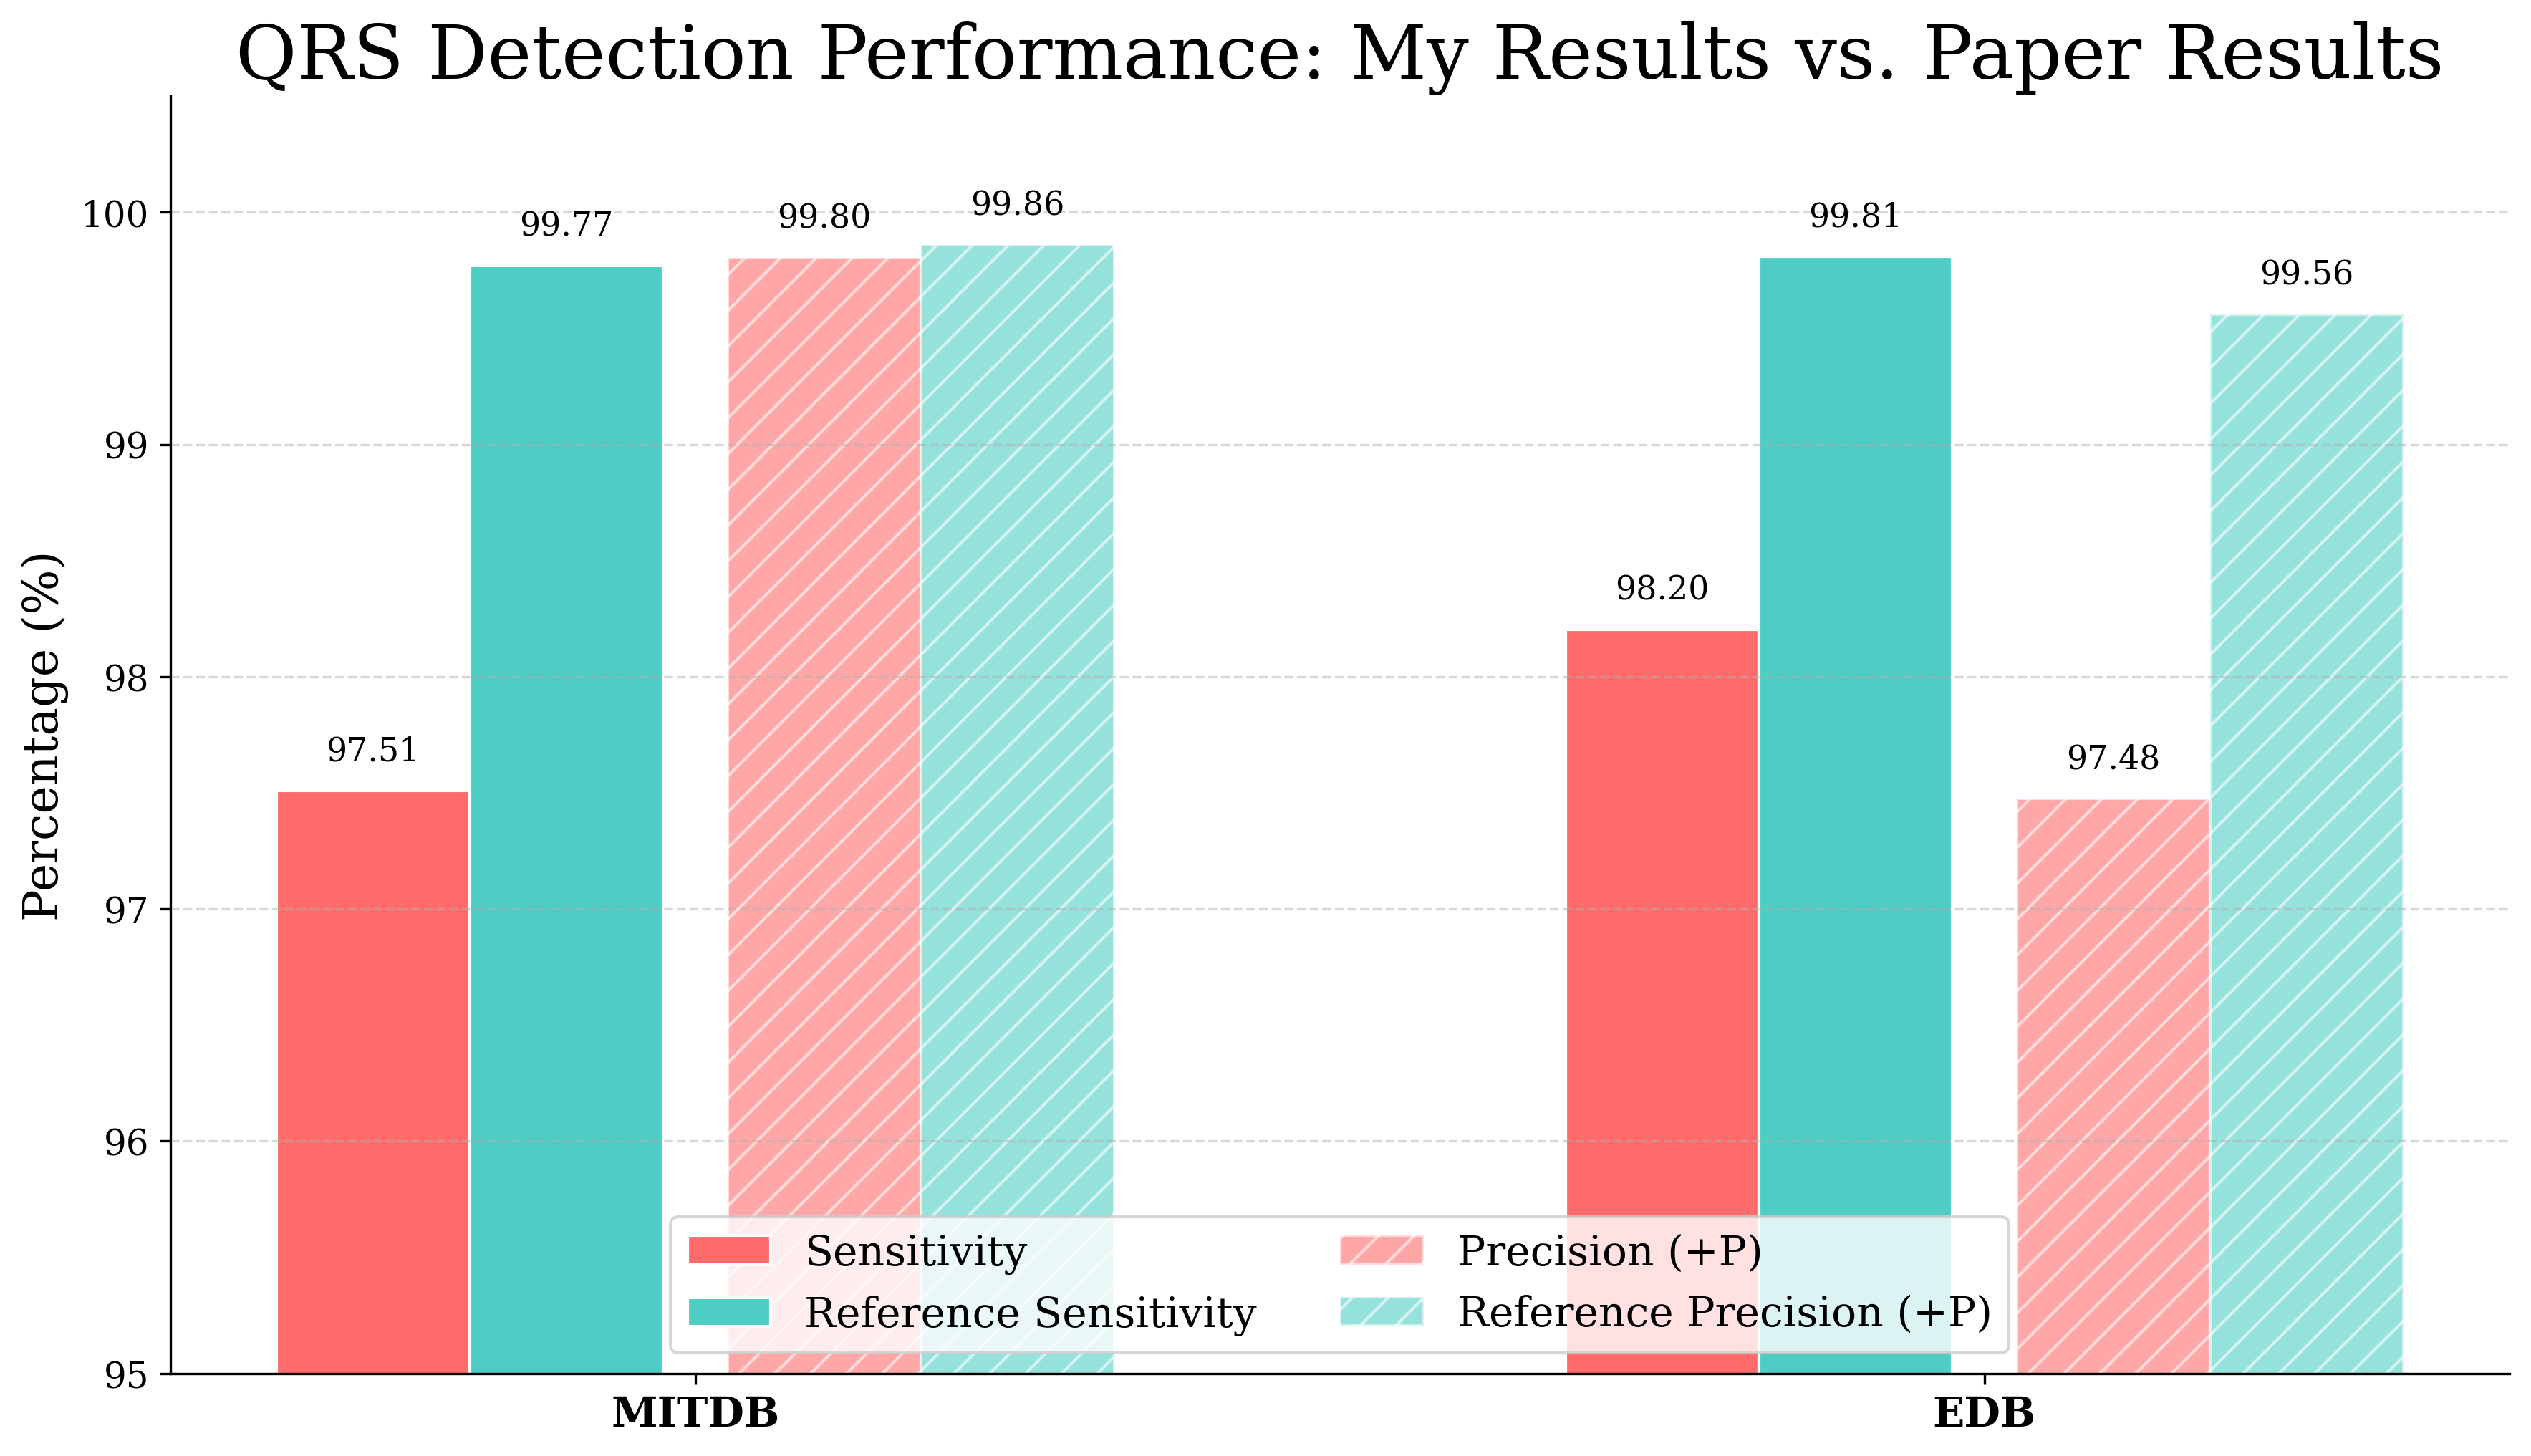

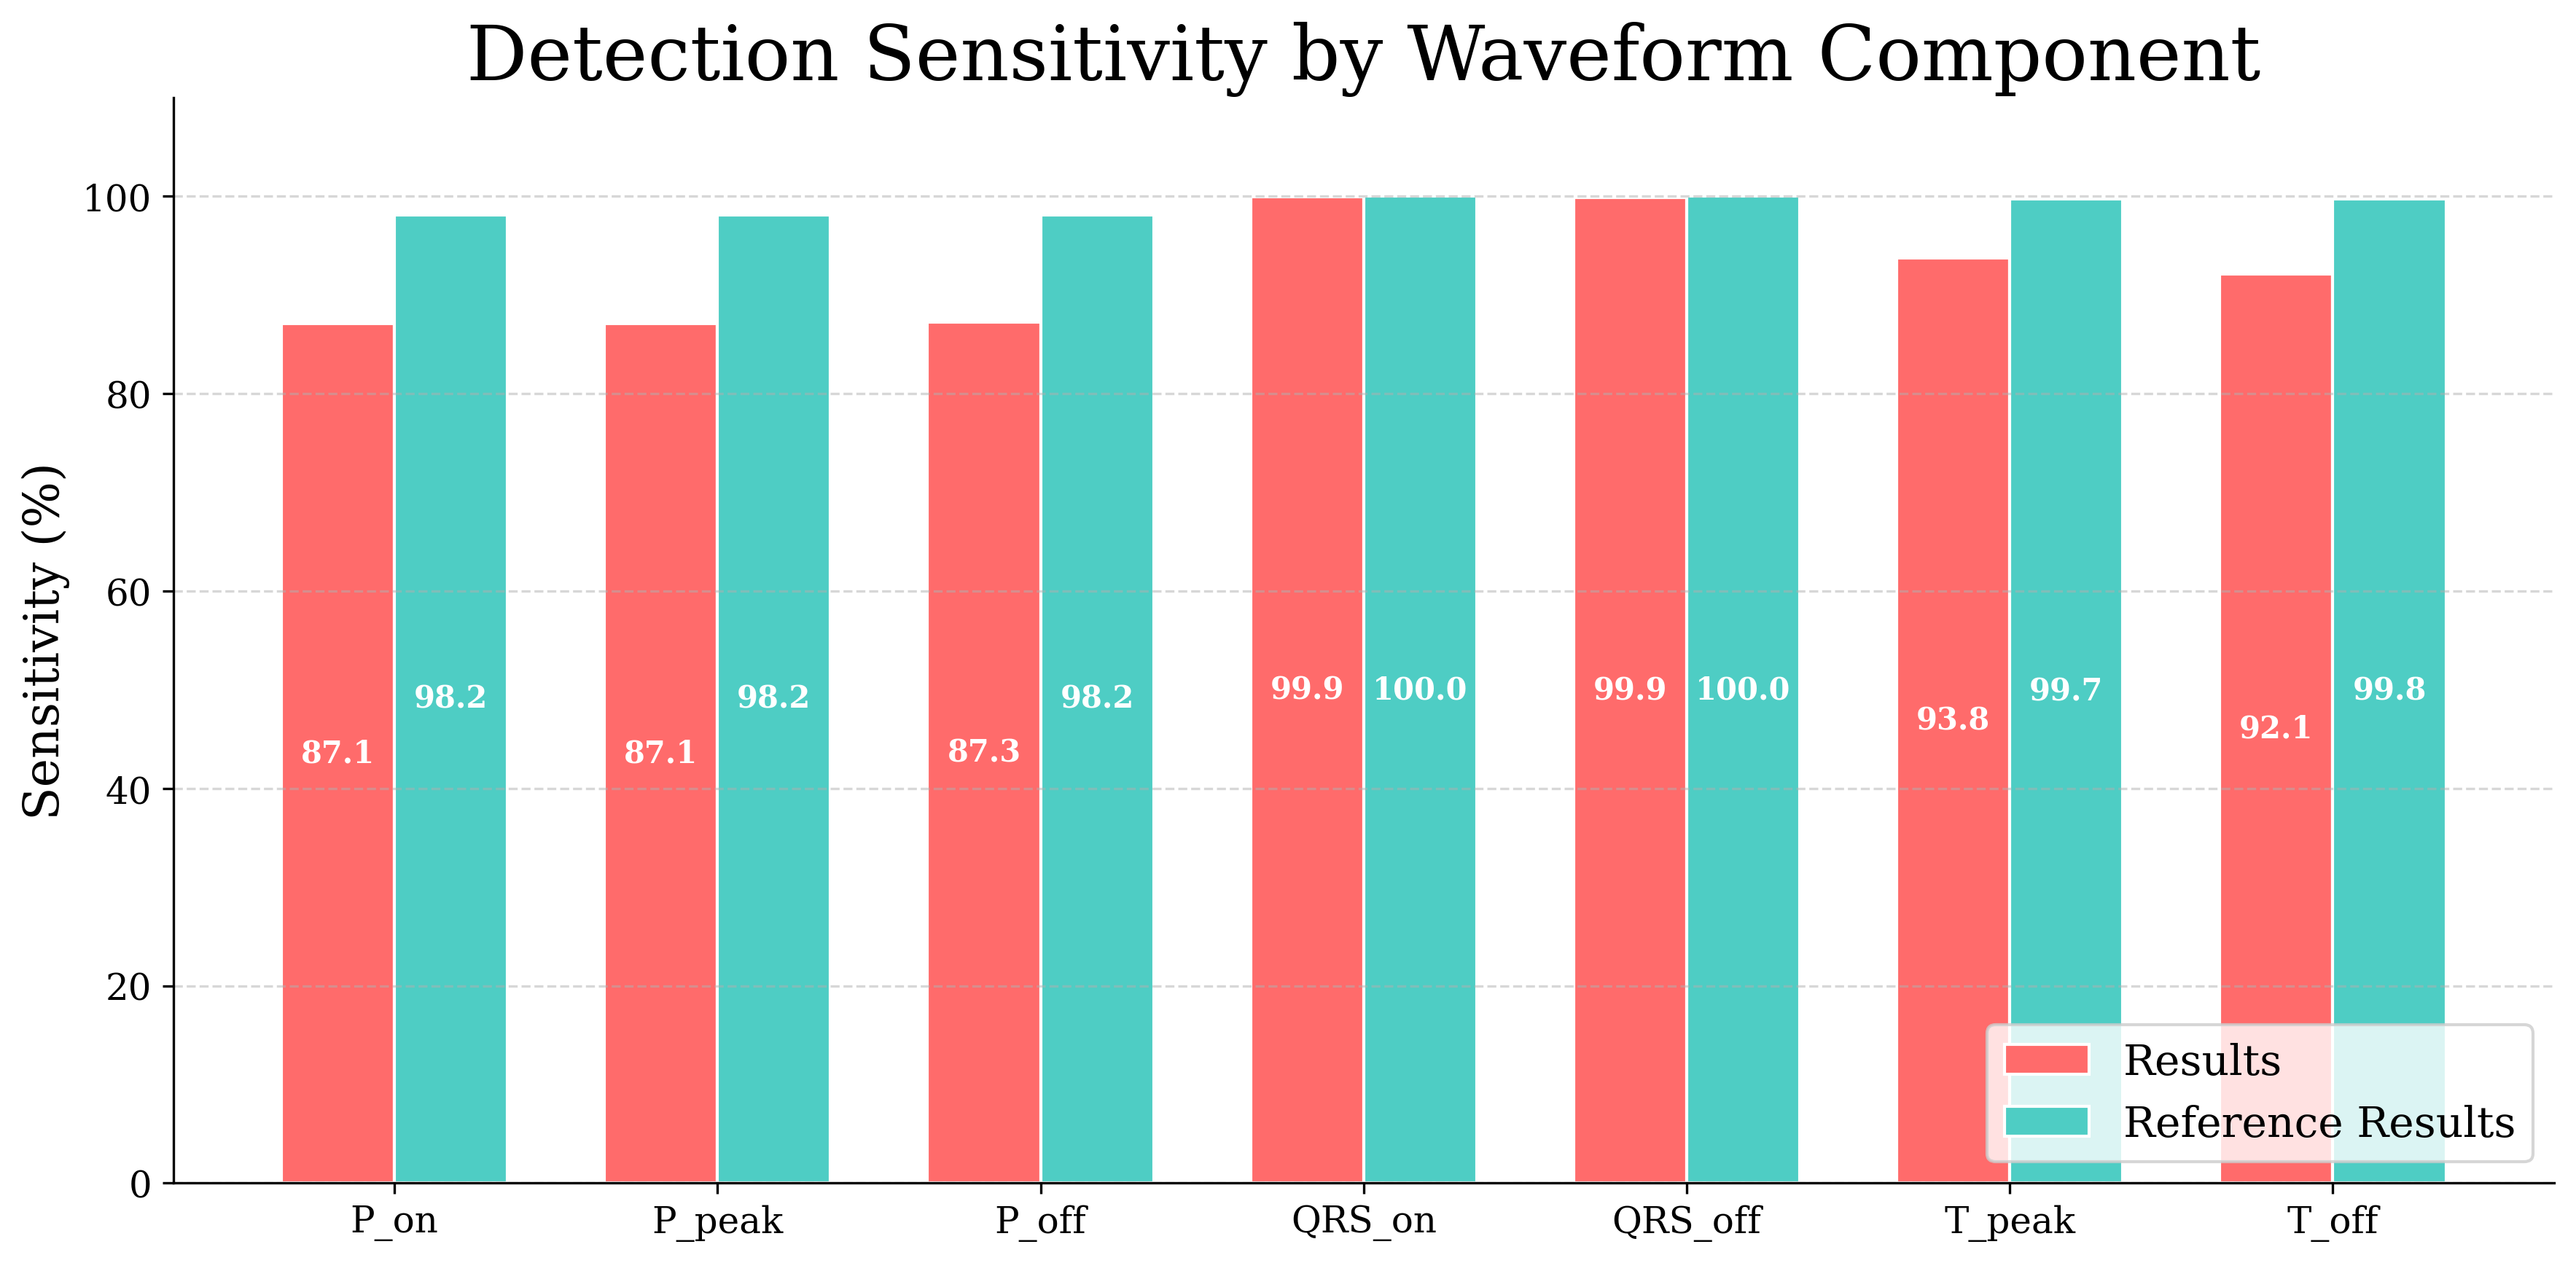

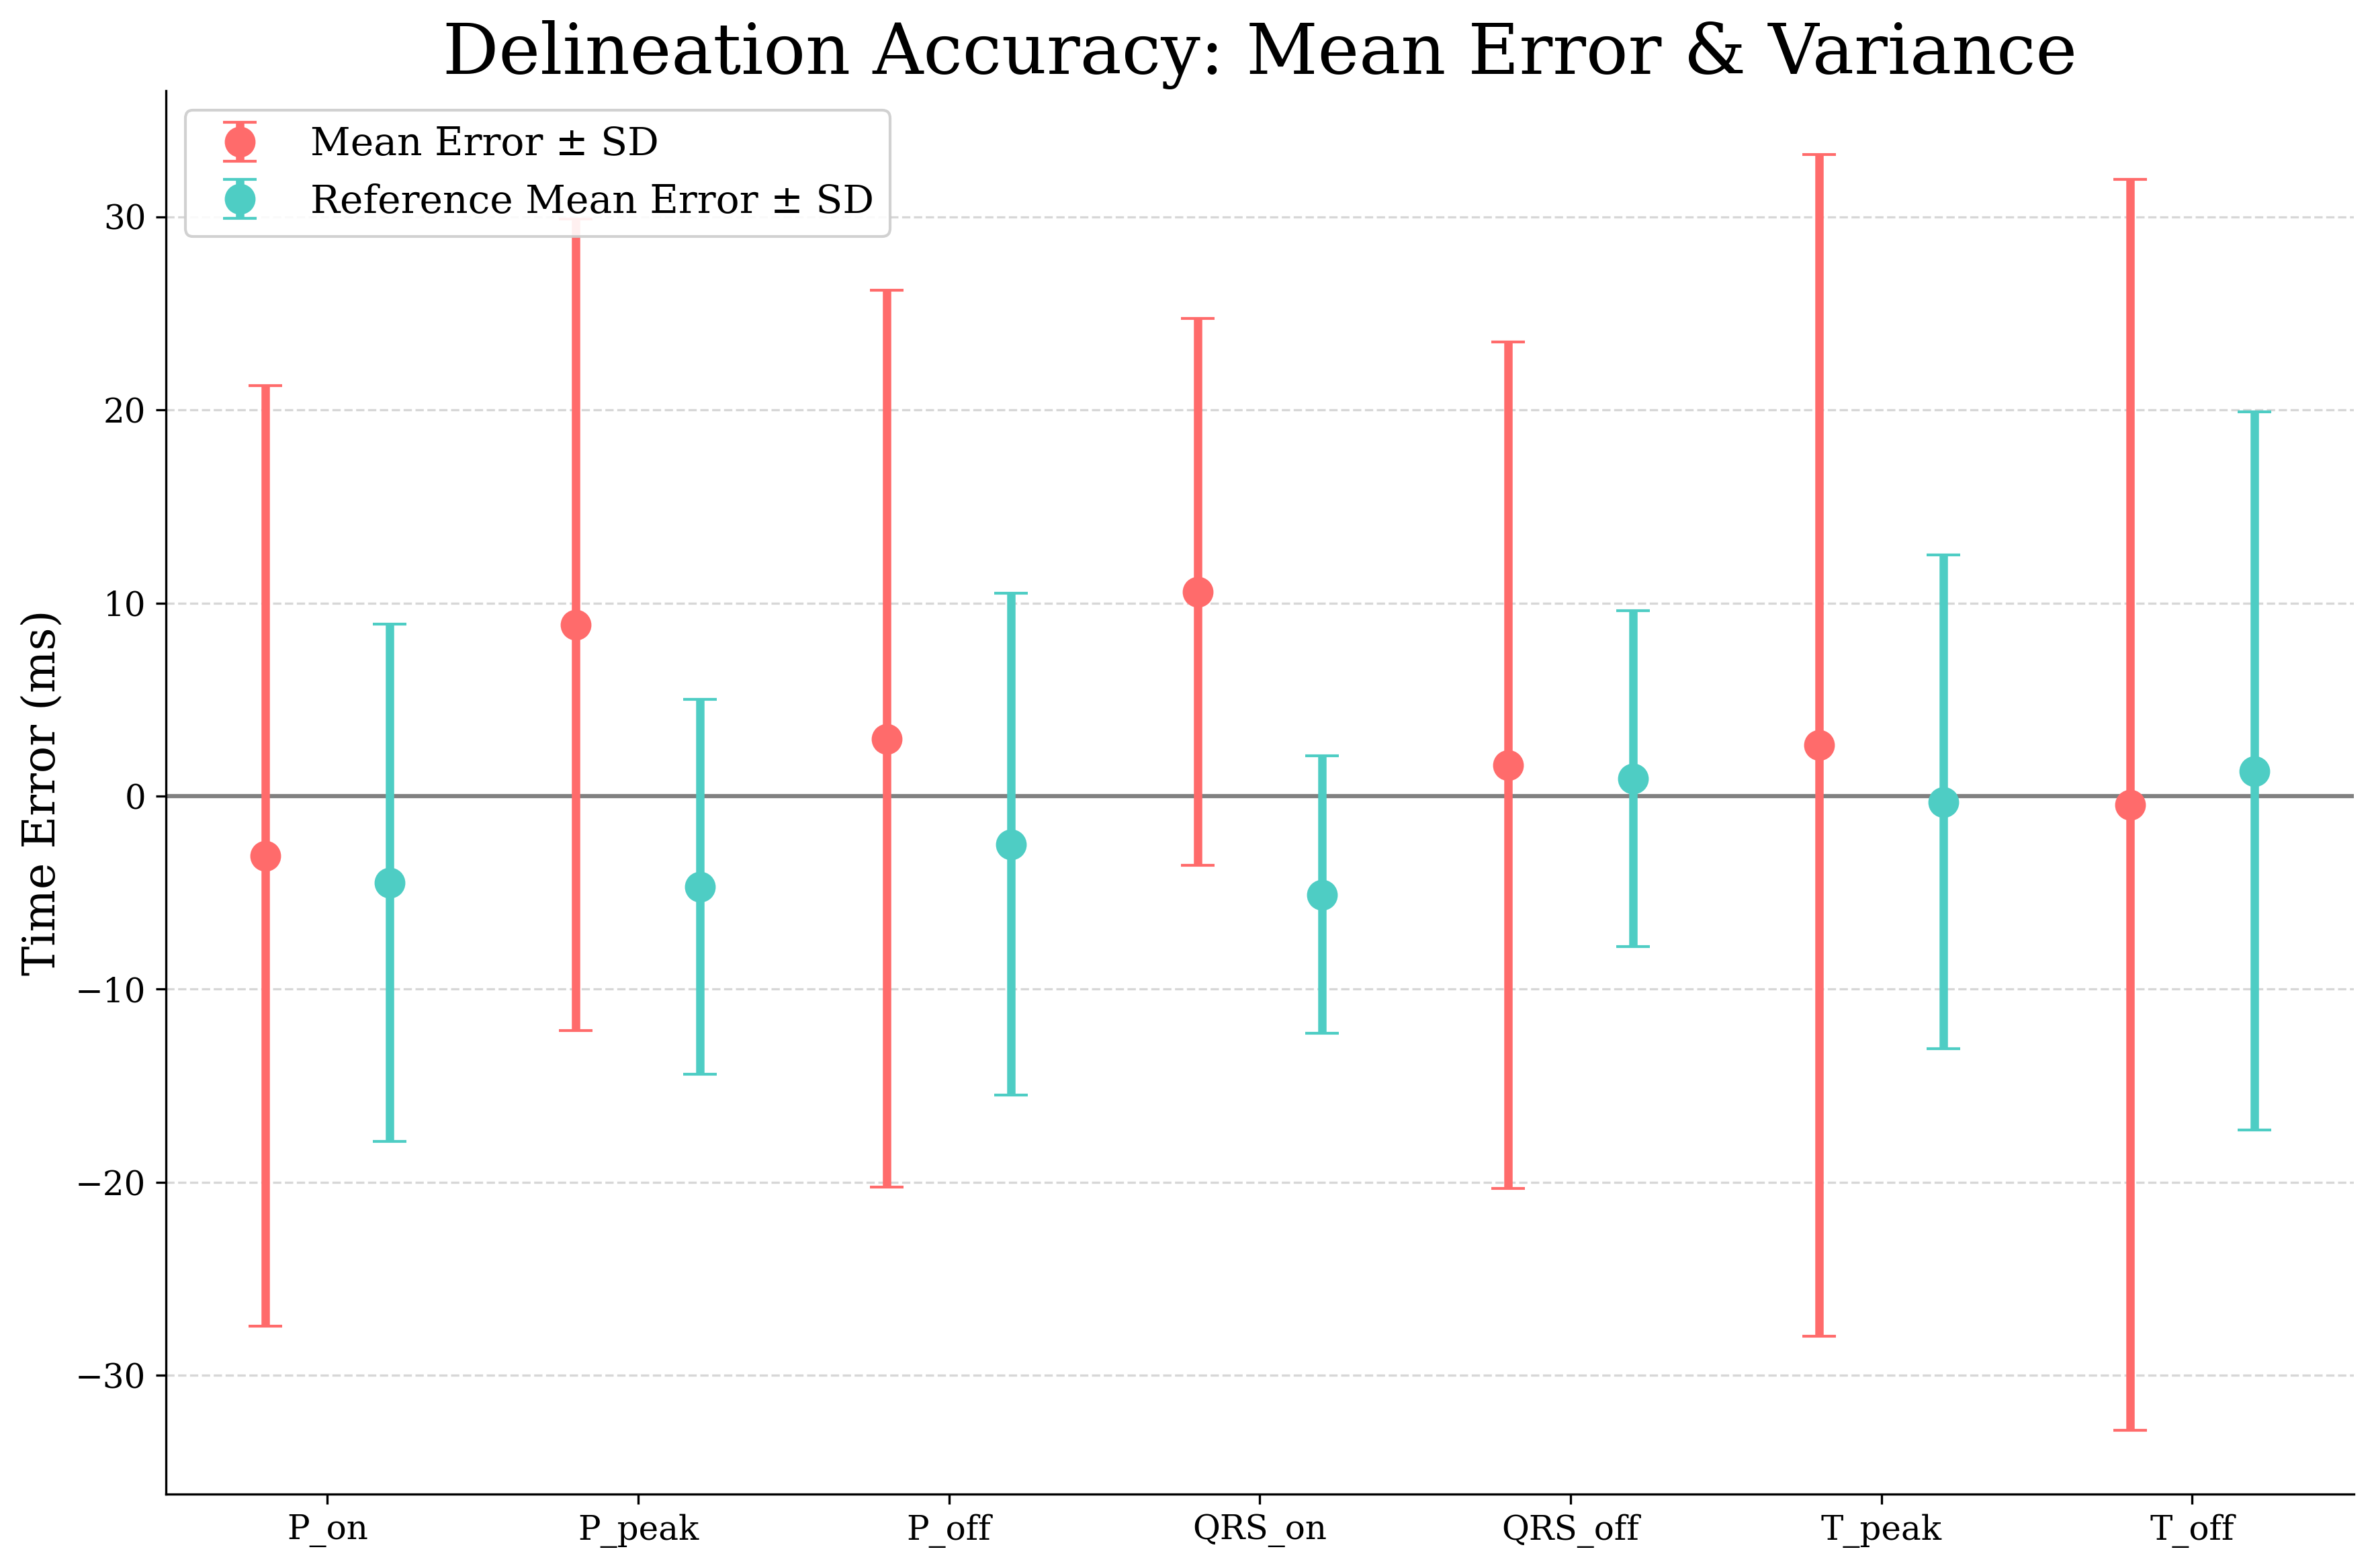

In [6]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import pandas as pd
import os

# Check for Alice font, otherwise fallback
font_names = [f.name for f in fm.fontManager.ttflist]
target_font = 'Alice' if 'Alice' in font_names else 'serif'

# Set global style
plt.rcParams.update({
    'font.family': target_font,
    'font.size': 14,
    'axes.titlesize': 25,
    'axes.labelsize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.dpi': 300,
    'figure.figsize': (10, 6),
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# --- LOAD DATA FROM CSV FILES ---
results_dir = '/home/utente/bsp_project/BSP-project/results'

# Load MITDB and EDB results for QRS detection
df_mitdb = pd.read_csv(os.path.join(results_dir, 'MITDB_results.csv'))
df_edb = pd.read_csv(os.path.join(results_dir, 'EDB_results.csv'))

# Get aggregate results (last row)
mitdb_agg = df_mitdb[df_mitdb['Record'] == 'AGGREGATE'].iloc[0]
edb_agg = df_edb[df_edb['Record'] == 'AGGREGATE'].iloc[0]

# Extract QRS detection metrics
datasets = ['MITDB', 'EDB']
qrs_my_results = np.array([
    [mitdb_agg['Sensitivity_%'], mitdb_agg['Positive_Predictivity_%']],
    [edb_agg['Sensitivity_%'], edb_agg['Positive_Predictivity_%']]
])

# Paper results (reference values)
qrs_paper_results = np.array([[99.77, 99.86], [99.81, 99.56]])

# Load QTDB results
df_qtdb_detection = pd.read_csv(os.path.join(results_dir, 'QTDB_detection_statistics.csv'))
df_qtdb_errors = pd.read_csv(os.path.join(results_dir, 'QTDB_delineation_errors.csv'))

# Extract fiducial points data
fiducials = df_qtdb_detection['Fiducial'].tolist()
sens_my_results = df_qtdb_detection['Sensitivity_%'].fillna(0).tolist()

# Paper results for sensitivity (reference values)
sens_paper_results = [98.15, 98.15, 98.15, 100.0, 100.0, 99.72, 99.77]

# Extract error statistics
err_mean_my = df_qtdb_errors['Mean_Error_ms'].fillna(0).tolist()
err_std_my = df_qtdb_errors['Std_Dev_ms'].fillna(0).tolist()

# Paper results for errors (reference values)
err_mean_paper = [-4.5, -4.7, -2.5, -5.1, 0.9, -0.3, 1.3]
err_std_paper = [13.4, 9.7, 13.0, 7.2, 8.7, 12.8, 18.6]

# Colors (Canva-friendly palette)
color_my = '#FF6B6B'      # Coral Red
color_paper = '#4ECDC4'   # Teal/Turquoise
color_my_dark = '#C44D4D'
color_paper_dark = '#3B9A94'

print(f"Font used: {target_font}")
print(f"\nLoaded data:")
print(f"MITDB - Se: {qrs_my_results[0,0]:.2f}%, P+: {qrs_my_results[0,1]:.2f}%")
print(f"EDB - Se: {qrs_my_results[1,0]:.2f}%, P+: {qrs_my_results[1,1]:.2f}%")
print(f"QTDB Fiducials: {', '.join(fiducials)}")

# --- PLOT 1: QRS Performance ---
fig1, ax1 = plt.subplots(figsize=(12, 7))

# Layout: Group by Metric within Dataset to make it clearer
# X-axis: MITDB, EDB
# Bars: (Se My, Se Paper) -- gap -- (P+ My, P+ Paper)
bar_width = 0.15
x = np.arange(len(datasets))
# Offsets
pos_se_my = x - 0.25
pos_se_paper = x - 0.10
pos_pp_my = x + 0.10
pos_pp_paper = x + 0.25

rects1 = ax1.bar(pos_se_my, qrs_my_results[:, 0], bar_width, label='Sensitivity', color=color_my, edgecolor='white')
rects2 = ax1.bar(pos_se_paper, qrs_paper_results[:, 0], bar_width, label='Reference Sensitivity', color=color_paper, edgecolor='white')

rects3 = ax1.bar(pos_pp_my, qrs_my_results[:, 1], bar_width, label='Precision (+P)', color=color_my, alpha=0.6, hatch='//', edgecolor='white')
rects4 = ax1.bar(pos_pp_paper, qrs_paper_results[:, 1], bar_width, label='Reference Precision (+P)', color=color_paper, alpha=0.6, hatch='//', edgecolor='white')

# Add value labels on top of bars
for i in range(len(datasets)):
    ax1.text(pos_se_my[i], qrs_my_results[i, 0] + 0.1, f'{qrs_my_results[i, 0]:.2f}', ha='center', va='bottom', fontsize=11)
    ax1.text(pos_se_paper[i], qrs_paper_results[i, 0] + 0.1, f'{qrs_paper_results[i, 0]:.2f}', ha='center', va='bottom', fontsize=11)
    ax1.text(pos_pp_my[i], qrs_my_results[i, 1] + 0.1, f'{qrs_my_results[i, 1]:.2f}', ha='center', va='bottom', fontsize=11)
    ax1.text(pos_pp_paper[i], qrs_paper_results[i, 1] + 0.1, f'{qrs_paper_results[i, 1]:.2f}', ha='center', va='bottom', fontsize=11)

# Labels and formatting
ax1.set_ylabel('Percentage (%)')
ax1.set_title('QRS Detection Performance: My Results vs. Paper Results')
ax1.set_xticks(x)
ax1.set_xticklabels(datasets, fontsize=14, fontweight='bold')
ax1.set_ylim(95, 100.5) # Zoom for clarity

# Add dashed line to separate Se and P+ groups visually? No, the gap is enough.
# Legend - manually ordered
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles, labels, loc='lower center', ncol=2, frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig1.savefig('../figures/plot1_qrs_performance.png', dpi=300)
plt.show()

# --- PLOT 2: Sensitivity ---
fig2, ax2 = plt.subplots(figsize=(12, 6))

x_sens = np.arange(len(fiducials))
width_sens = 0.35

ax2.bar(x_sens - width_sens/2, sens_my_results, width_sens, label='Results', color=color_my, edgecolor='white')
ax2.bar(x_sens + width_sens/2, sens_paper_results, width_sens, label='Reference Results', color=color_paper, edgecolor='white')

ax2.set_ylabel('Sensitivity (%)')
ax2.set_title('Detection Sensitivity by Waveform Component')
ax2.set_xticks(x_sens)
ax2.set_xticklabels(fiducials)
ax2.set_ylim(0, 110)
ax2.legend(loc='lower right')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Add values inside bars
for i, v in enumerate(sens_my_results):
    ax2.text(i - width_sens/2, v/2, f"{v:.1f}", ha='center', va='center', fontsize=10, color='white', fontweight='bold')

for i, v in enumerate(sens_paper_results):
    ax2.text(i + width_sens/2, v/2, f"{v:.1f}", ha='center', va='center', fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
fig2.savefig('../figures/plot2_sensitivity.png', dpi=300)
plt.show()

# --- PLOT 3: Time Error ---
fig3, ax3 = plt.subplots(figsize=(12, 8))

x_err = np.arange(len(fiducials))
shift = 0.2

# Zero line
ax3.axhline(0, color='gray', linewidth=1.5, linestyle='-')

# Error Bars
# My Results
ax3.errorbar(x_err - shift, err_mean_my, yerr=err_std_my, fmt='o', 
             color=color_my, ecolor=color_my, elinewidth=3, capsize=6, markersize=10, 
             label='Mean Error ± SD')

# Paper Results
ax3.errorbar(x_err + shift, err_mean_paper, yerr=err_std_paper, fmt='o', 
             color=color_paper, ecolor=color_paper, elinewidth=3, capsize=6, markersize=10, 
             label='Reference Mean Error ± SD')

ax3.set_ylabel('Time Error (ms)')
ax3.set_title('Delineation Accuracy: Mean Error & Variance')
ax3.set_xticks(x_err)
ax3.set_xticklabels(fiducials, fontsize=12)
ax3.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
ax3.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig3.savefig('../figures/plot3_time_error.png', dpi=300)
plt.show()


# Analysis of Algorithm Performance Issues
Understanding where the R peak detection struggles most

In [7]:
# Load per-record results for MITDB and EDB (excluding aggregate row)
df_mitdb_records = df_mitdb[df_mitdb['Record'] != 'AGGREGATE'].copy()
df_edb_records = df_edb[df_edb['Record'] != 'AGGREGATE'].copy()

# Add database column
df_mitdb_records['Database'] = 'MITDB'
df_edb_records['Database'] = 'EDB'

# Combine both databases
df_combined = pd.concat([df_mitdb_records, df_edb_records], ignore_index=True)

# Calculate error rates
df_combined['FP_Rate'] = (df_combined['FP'] / df_combined['Total_Annotations']) * 100
df_combined['FN_Rate'] = (df_combined['FN'] / df_combined['Total_Annotations']) * 100

# Sort by sensitivity to find worst performers
df_worst_sensitivity = df_combined.nsmallest(15, 'Sensitivity_%')

print("Records with LOWEST Sensitivity (Worst R-peak Detection):")
print("="*80)
print(df_worst_sensitivity[['Record', 'Database', 'Sensitivity_%', 'Positive_Predictivity_%', 'FP', 'FN', 'Total_Annotations']].to_string(index=False))

print("\n\nRecords with HIGHEST False Negative Rate:")
print("="*80)
df_worst_fn = df_combined.nsmallest(15, 'Sensitivity_%')
print(df_worst_fn[['Record', 'Database', 'FN', 'FN_Rate', 'Sensitivity_%', 'Total_Annotations']].to_string(index=False))

print("\n\nRecords with HIGHEST False Positive Rate:")
print("="*80)
df_worst_fp = df_combined.nsmallest(15, 'Positive_Predictivity_%')
print(df_worst_fp[['Record', 'Database', 'FP', 'FP_Rate', 'Positive_Predictivity_%', 'Total_Annotations']].to_string(index=False))

Records with LOWEST Sensitivity (Worst R-peak Detection):
Record Database  Sensitivity_%  Positive_Predictivity_%   FP  FN  Total_Annotations
   231    MITDB      78.110945               100.000000    0 438               2001
   230    MITDB      91.520587               100.000000    0 208               2453
 e0817      EDB      92.832634                94.624352  415 564               7869
 e0159      EDB      92.878244                88.982109 1090 675               9478
   200    MITDB      93.055056                99.884125    3 193               2779
   219    MITDB      93.133420               100.000000    0 158               2301
   222    MITDB      94.205109                99.919127    2 152               2623
 e0415      EDB      94.711375                94.510801  648 623              11780
 e0155      EDB      94.890944                86.728061 1225 431               8436
 e0116      EDB      94.910831                97.367247  118 234               4598
   119    MITDB   

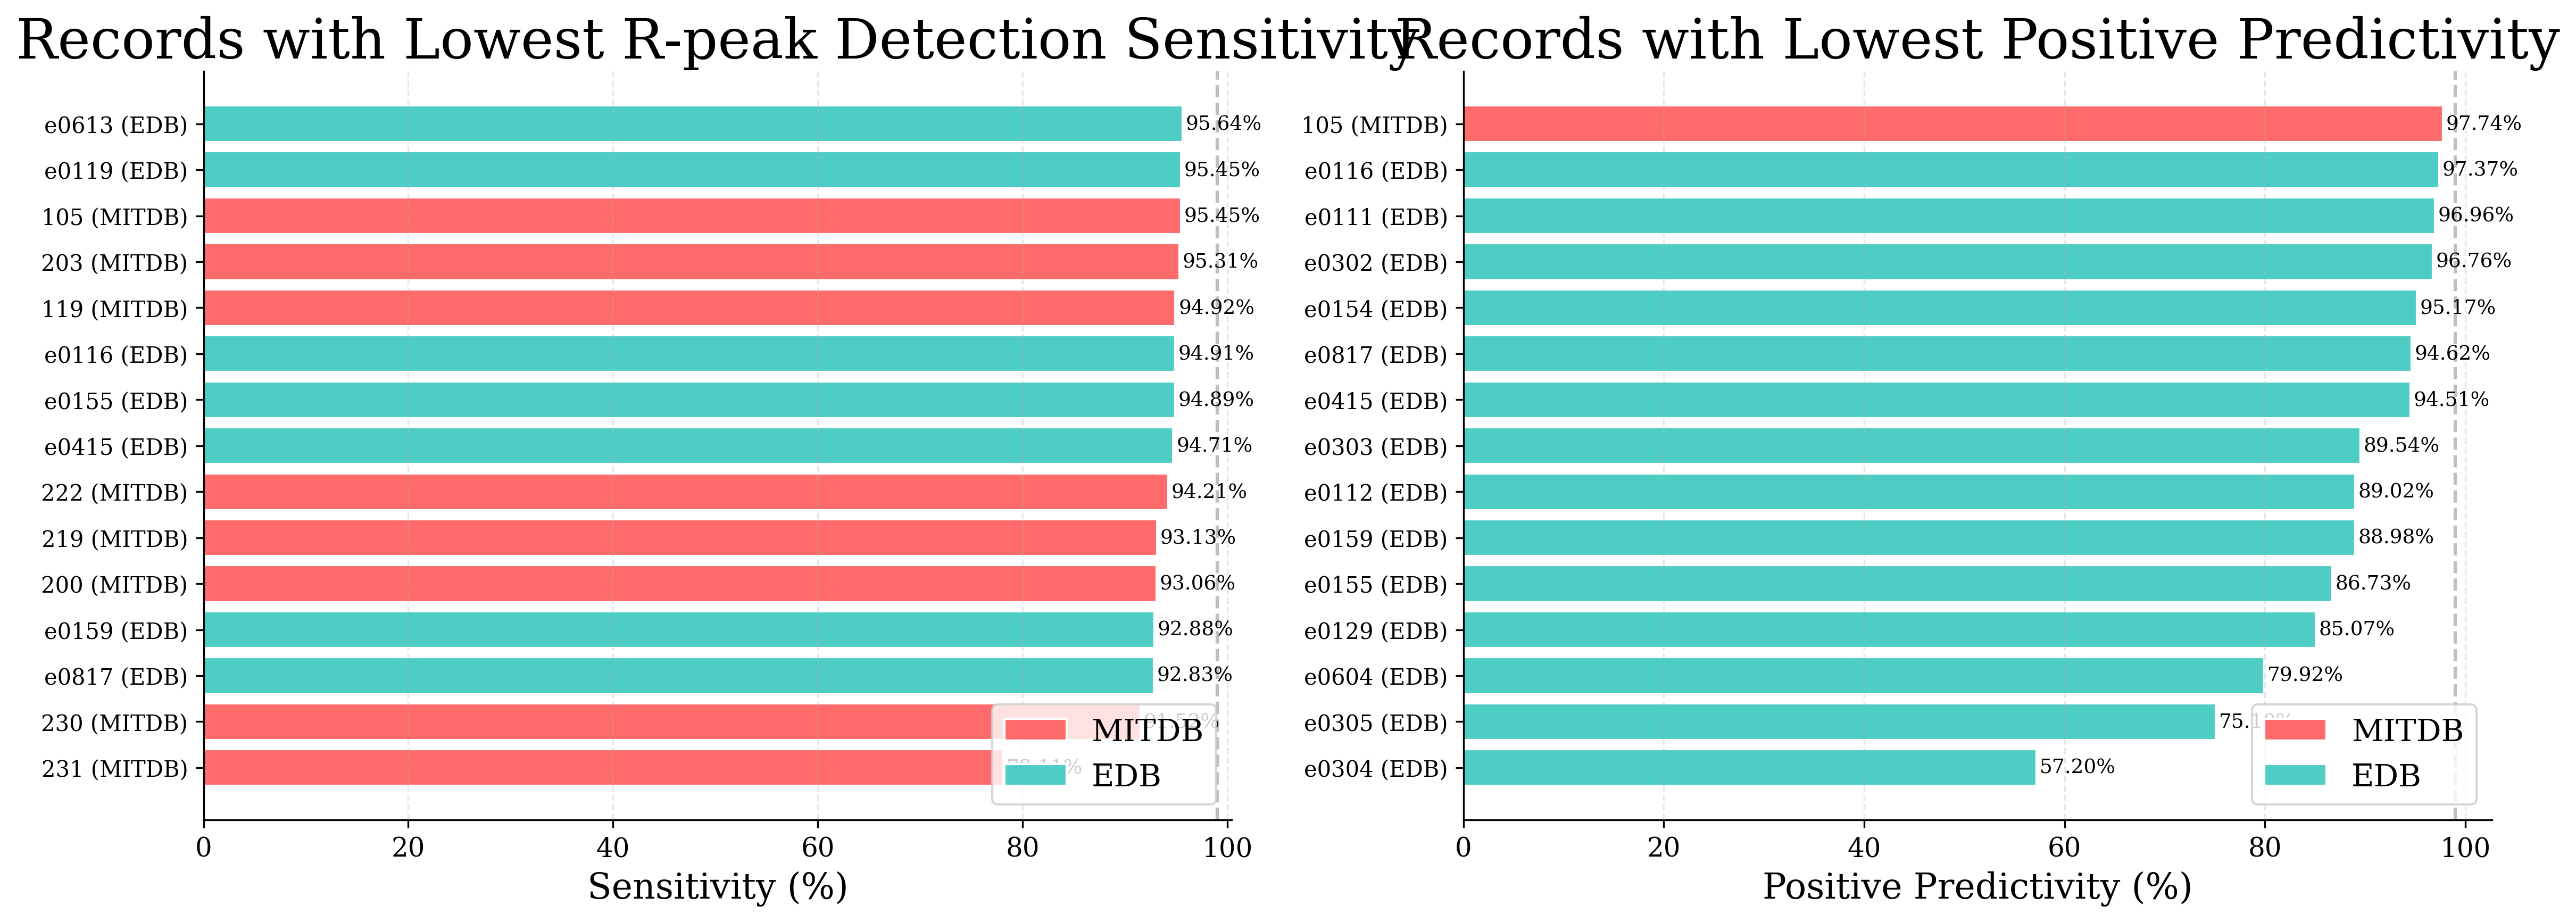

In [8]:
# --- PLOT 4: Records with Lowest Sensitivity ---
fig4, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(16, 6))

# Top 15 worst performers by sensitivity
worst_15 = df_combined.nsmallest(15, 'Sensitivity_%').sort_values('Sensitivity_%')
colors_db = [color_my if db == 'MITDB' else color_paper for db in worst_15['Database']]

ax4a.barh(range(len(worst_15)), worst_15['Sensitivity_%'], color=colors_db, edgecolor='white')
ax4a.set_yticks(range(len(worst_15)))
ax4a.set_yticklabels([f"{rec} ({db})" for rec, db in zip(worst_15['Record'], worst_15['Database'])], fontsize=10)
ax4a.set_xlabel('Sensitivity (%)')
ax4a.set_title('Records with Lowest R-peak Detection Sensitivity')
ax4a.axvline(99, color='gray', linestyle='--', alpha=0.5, label='99% threshold')
ax4a.legend()
ax4a.grid(axis='x', linestyle='--', alpha=0.3)

# Add values on bars
for i, (idx, row) in enumerate(worst_15.iterrows()):
    ax4a.text(row['Sensitivity_%'] + 0.3, i, f"{row['Sensitivity_%']:.2f}%", 
             va='center', fontsize=9)

# Top 15 worst performers by positive predictivity
worst_pp_15 = df_combined.nsmallest(15, 'Positive_Predictivity_%').sort_values('Positive_Predictivity_%')
colors_db_pp = [color_my if db == 'MITDB' else color_paper for db in worst_pp_15['Database']]

ax4b.barh(range(len(worst_pp_15)), worst_pp_15['Positive_Predictivity_%'], color=colors_db_pp, edgecolor='white')
ax4b.set_yticks(range(len(worst_pp_15)))
ax4b.set_yticklabels([f"{rec} ({db})" for rec, db in zip(worst_pp_15['Record'], worst_pp_15['Database'])], fontsize=10)
ax4b.set_xlabel('Positive Predictivity (%)')
ax4b.set_title('Records with Lowest Positive Predictivity')
ax4b.axvline(99, color='gray', linestyle='--', alpha=0.5, label='99% threshold')
ax4b.legend()
ax4b.grid(axis='x', linestyle='--', alpha=0.3)

# Add values on bars
for i, (idx, row) in enumerate(worst_pp_15.iterrows()):
    ax4b.text(row['Positive_Predictivity_%'] + 0.3, i, f"{row['Positive_Predictivity_%']:.2f}%", 
             va='center', fontsize=9)

# Add custom legend for database colors
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color_my, edgecolor='white', label='MITDB'),
                   Patch(facecolor=color_paper, edgecolor='white', label='EDB')]
ax4a.legend(handles=legend_elements, loc='lower right')
ax4b.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
fig4.savefig('../figures/plot4_worst_performers.png', dpi=300)
plt.show()

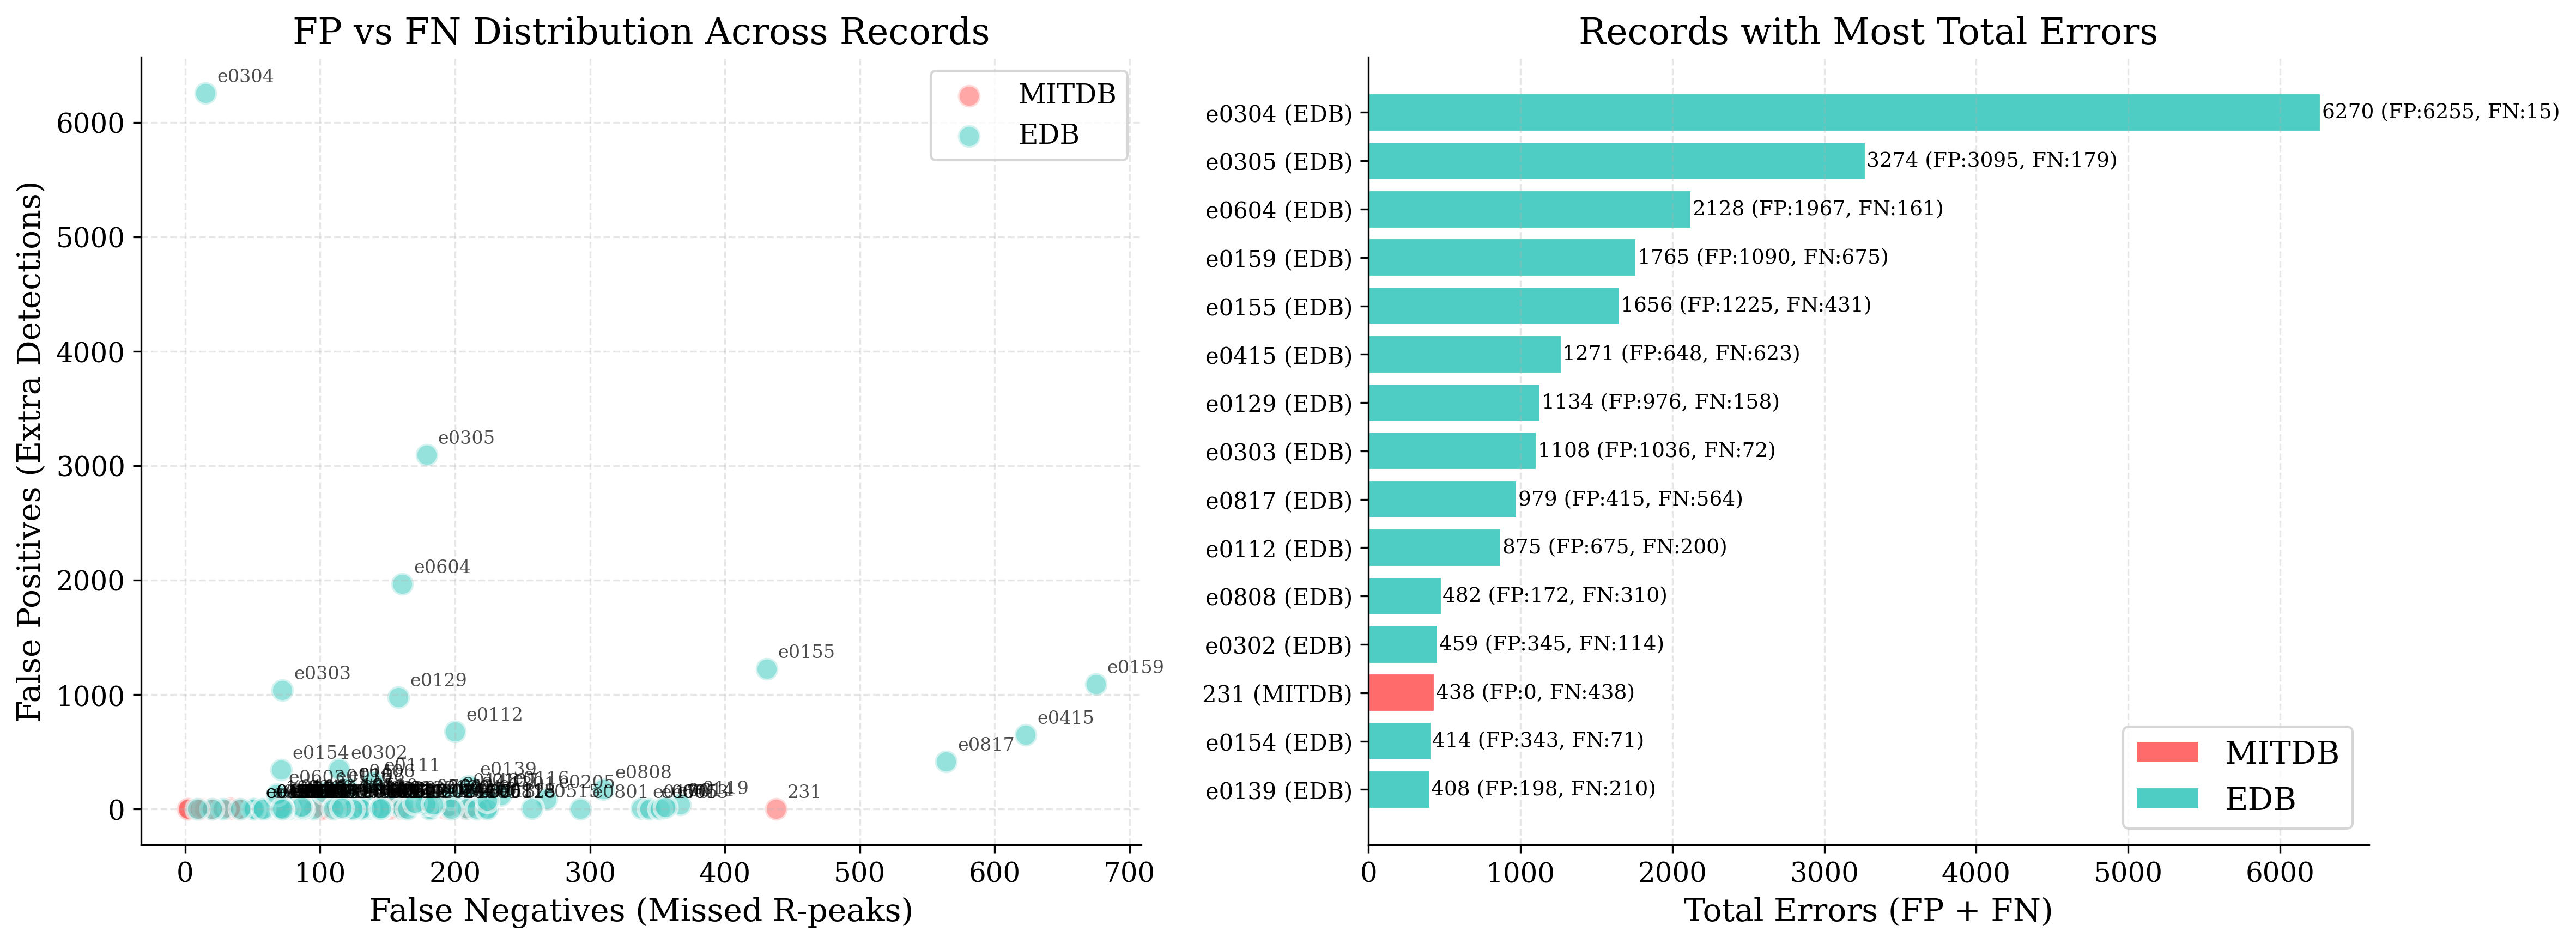

In [9]:
# --- PLOT 5: False Positive and False Negative Analysis ---
fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot: FP vs FN for each record
mitdb_scatter = df_combined[df_combined['Database'] == 'MITDB']
edb_scatter = df_combined[df_combined['Database'] == 'EDB']

ax5a.scatter(mitdb_scatter['FN'], mitdb_scatter['FP'], 
            s=100, alpha=0.6, color=color_my, label='MITDB', edgecolor='white', linewidth=1.5)
ax5a.scatter(edb_scatter['FN'], edb_scatter['FP'], 
            s=100, alpha=0.6, color=color_paper, label='EDB', edgecolor='white', linewidth=1.5)

ax5a.set_xlabel('False Negatives (Missed R-peaks)', fontsize=14)
ax5a.set_ylabel('False Positives (Extra Detections)', fontsize=14)
ax5a.set_title('FP vs FN Distribution Across Records', fontsize=16)
ax5a.legend(fontsize=12)
ax5a.grid(True, linestyle='--', alpha=0.3)

# Annotate outliers (records with high FP or FN)
combined_outliers = df_combined[(df_combined['FP'] > 50) | (df_combined['FN'] > 50)]
for idx, row in combined_outliers.iterrows():
    ax5a.annotate(row['Record'], 
                 (row['FN'], row['FP']), 
                 xytext=(5, 5), textcoords='offset points',
                 fontsize=8, alpha=0.7)

# Bar chart: Total errors (FP + FN) per record
df_combined['Total_Errors'] = df_combined['FP'] + df_combined['FN']
worst_errors = df_combined.nlargest(15, 'Total_Errors').sort_values('Total_Errors', ascending=True)
colors_errors = [color_my if db == 'MITDB' else color_paper for db in worst_errors['Database']]

bars = ax5b.barh(range(len(worst_errors)), worst_errors['Total_Errors'], color=colors_errors, edgecolor='white')
ax5b.set_yticks(range(len(worst_errors)))
ax5b.set_yticklabels([f"{rec} ({db})" for rec, db in zip(worst_errors['Record'], worst_errors['Database'])], fontsize=10)
ax5b.set_xlabel('Total Errors (FP + FN)', fontsize=14)
ax5b.set_title('Records with Most Total Errors', fontsize=16)
ax5b.grid(axis='x', linestyle='--', alpha=0.3)

# Add values and breakdown on bars
for i, (idx, row) in enumerate(worst_errors.iterrows()):
    total = row['Total_Errors']
    fp = row['FP']
    fn = row['FN']
    ax5b.text(total + 5, i, f"{total} (FP:{fp}, FN:{fn})", 
             va='center', fontsize=9)

# Add custom legend for database colors
legend_elements = [Patch(facecolor=color_my, edgecolor='white', label='MITDB'),
                   Patch(facecolor=color_paper, edgecolor='white', label='EDB')]
ax5b.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
fig5.savefig('../figures/plot5_error_analysis.png', dpi=300)
plt.show()

/tmp/ipykernel_6936/2266117237.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax6c.boxplot([mitdb_scatter['Sensitivity_%'], edb_scatter['Sensitivity_%']],
/tmp/ipykernel_6936/2266117237.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax6d.boxplot([mitdb_scatter['Positive_Predictivity_%'], edb_scatter['Positive_Predictivity_%']],


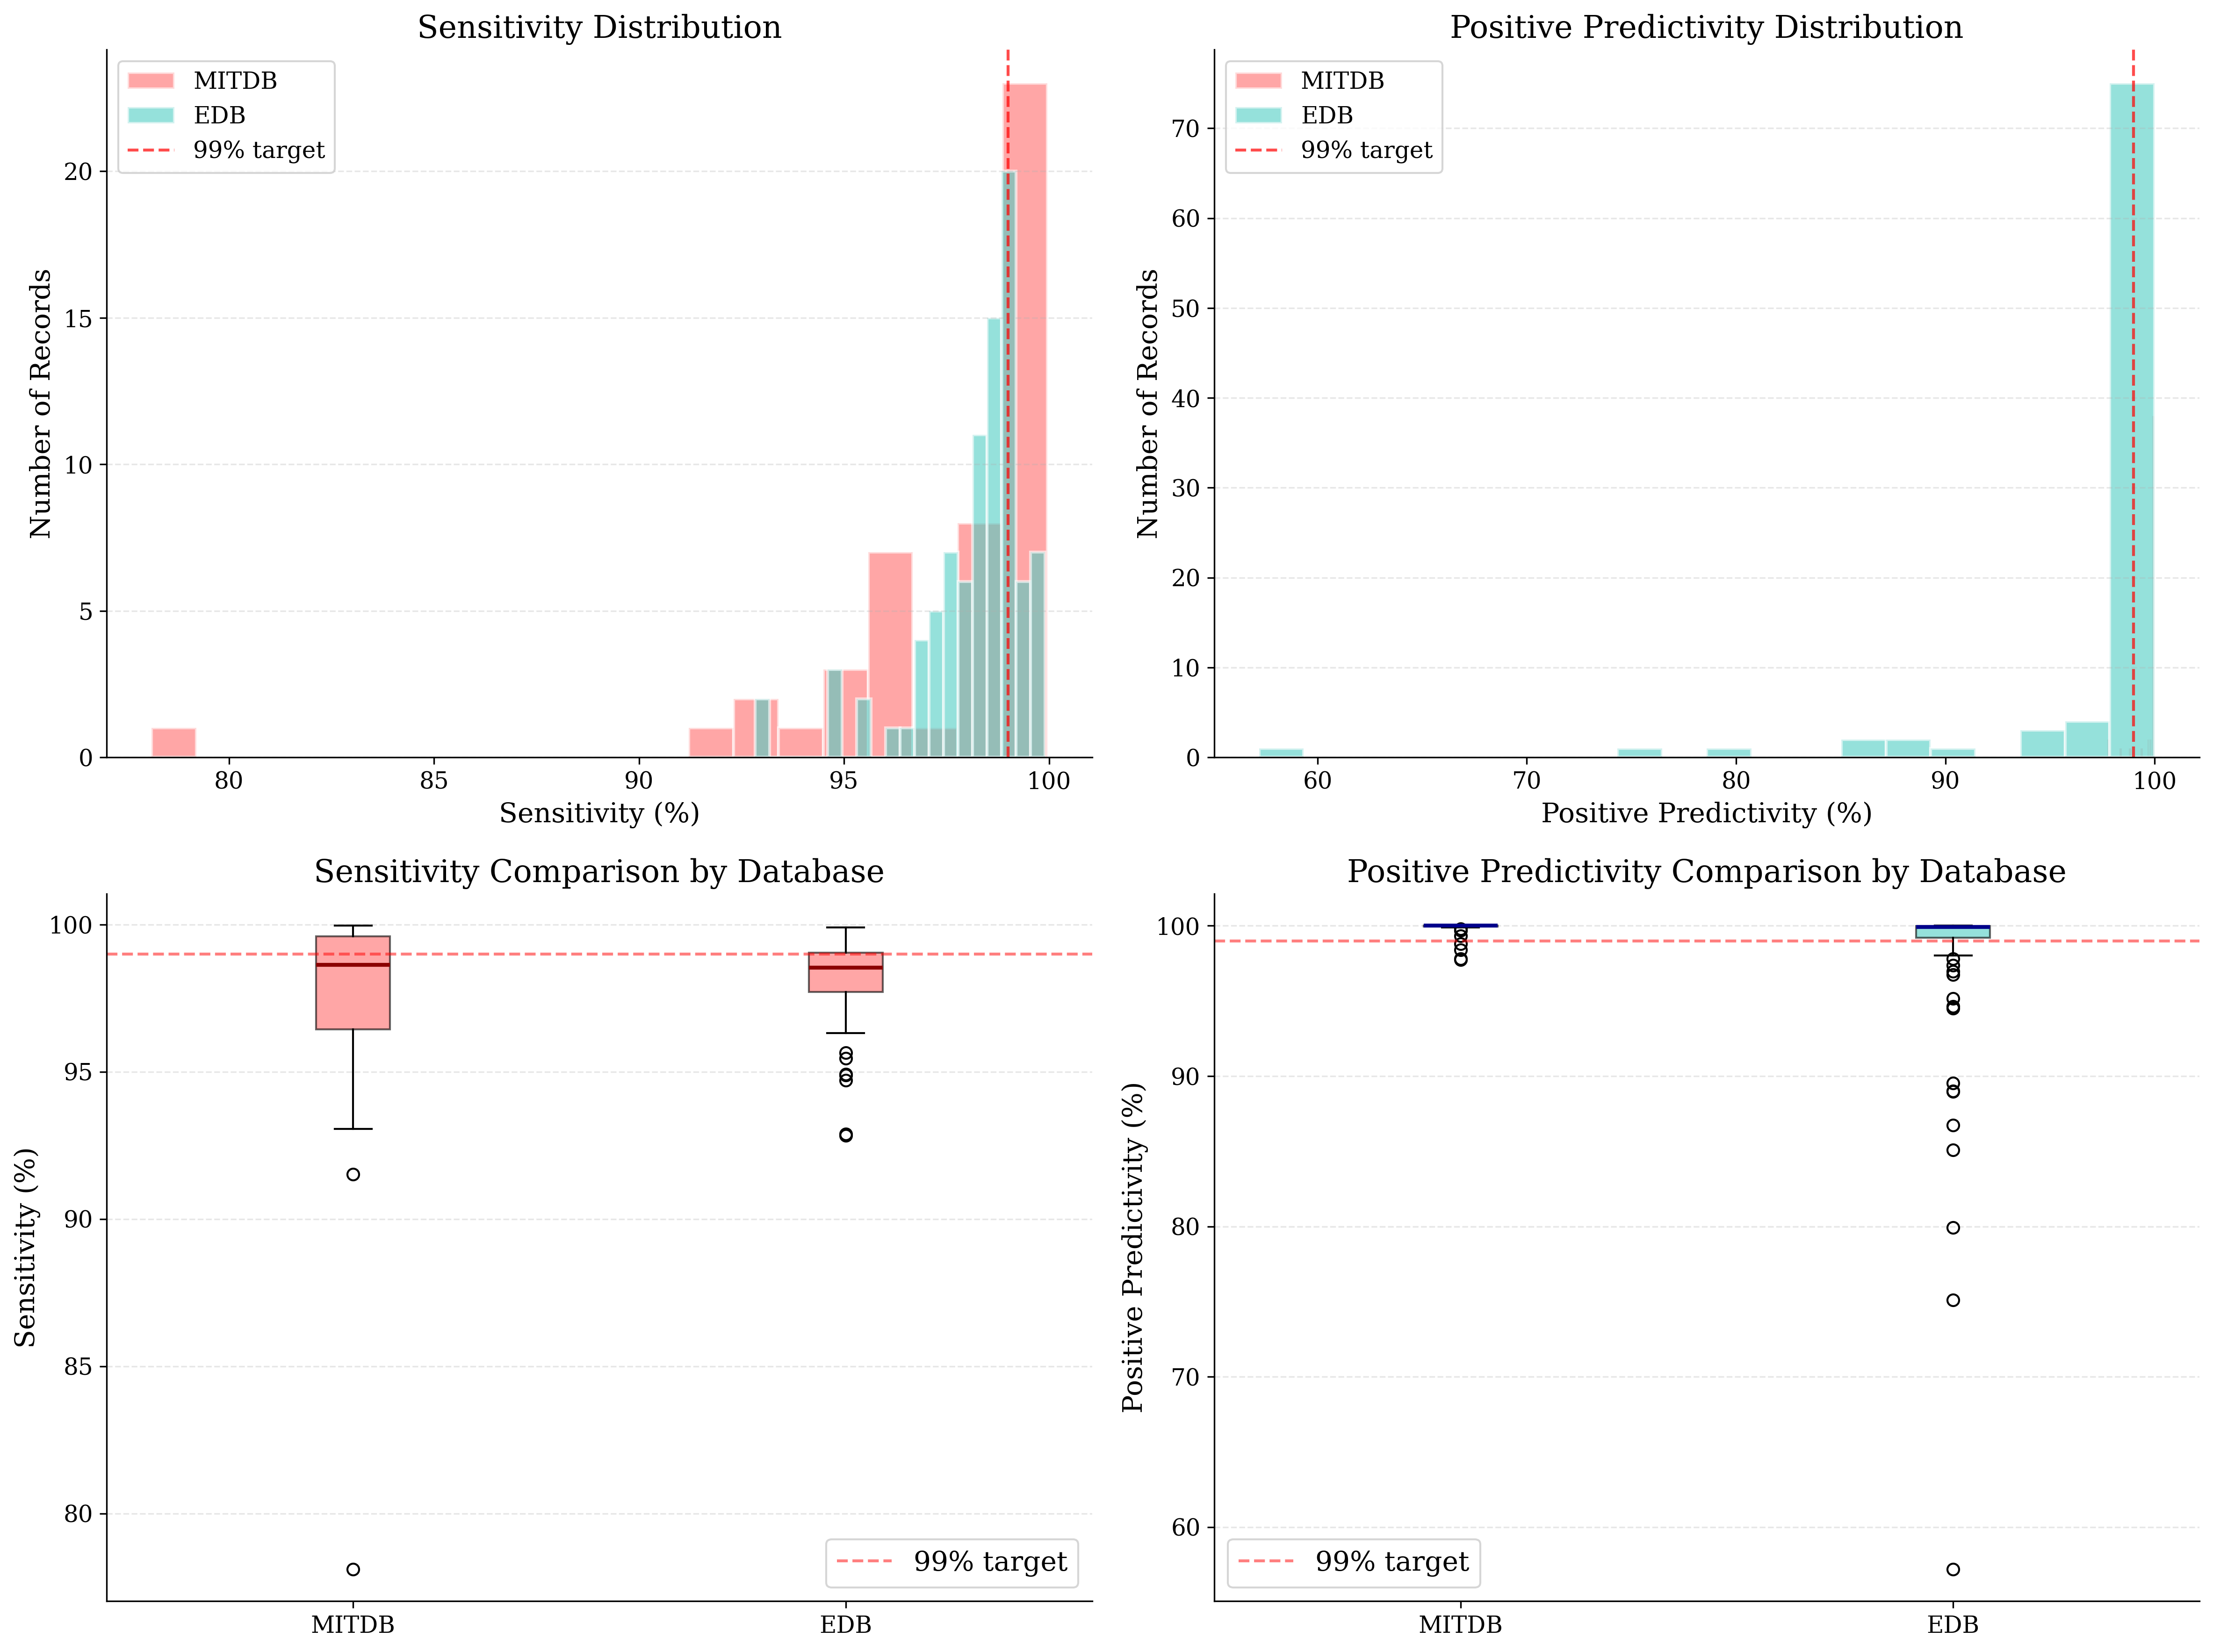



Summary Statistics:

MITDB:
  Mean Sensitivity: 97.54% (±3.59)
  Mean Positive Predictivity: 99.80% (±0.53)
  Records below 99% Se: 25 / 47
  Records below 99% P+: 4 / 47

EDB:
  Mean Sensitivity: 98.16% (±1.37)
  Mean Positive Predictivity: 97.82% (±6.10)
  Records below 99% Se: 66 / 90
  Records below 99% P+: 22 / 90


In [10]:
# --- PLOT 6: Performance Distribution Overview ---
fig6, ((ax6a, ax6b), (ax6c, ax6d)) = plt.subplots(2, 2, figsize=(16, 12))

# Histogram: Sensitivity distribution
ax6a.hist(mitdb_scatter['Sensitivity_%'], bins=20, alpha=0.6, color=color_my, 
         label='MITDB', edgecolor='white', linewidth=1.5)
ax6a.hist(edb_scatter['Sensitivity_%'], bins=20, alpha=0.6, color=color_paper, 
         label='EDB', edgecolor='white', linewidth=1.5)
ax6a.set_xlabel('Sensitivity (%)', fontsize=14)
ax6a.set_ylabel('Number of Records', fontsize=14)
ax6a.set_title('Sensitivity Distribution', fontsize=16)
ax6a.axvline(99, color='red', linestyle='--', alpha=0.7, label='99% target')
ax6a.legend(fontsize=12)
ax6a.grid(axis='y', linestyle='--', alpha=0.3)

# Histogram: Positive Predictivity distribution
ax6b.hist(mitdb_scatter['Positive_Predictivity_%'], bins=20, alpha=0.6, color=color_my, 
         label='MITDB', edgecolor='white', linewidth=1.5)
ax6b.hist(edb_scatter['Positive_Predictivity_%'], bins=20, alpha=0.6, color=color_paper, 
         label='EDB', edgecolor='white', linewidth=1.5)
ax6b.set_xlabel('Positive Predictivity (%)', fontsize=14)
ax6b.set_ylabel('Number of Records', fontsize=14)
ax6b.set_title('Positive Predictivity Distribution', fontsize=16)
ax6b.axvline(99, color='red', linestyle='--', alpha=0.7, label='99% target')
ax6b.legend(fontsize=12)
ax6b.grid(axis='y', linestyle='--', alpha=0.3)

# Box plot: Sensitivity by database
ax6c.boxplot([mitdb_scatter['Sensitivity_%'], edb_scatter['Sensitivity_%']], 
            labels=['MITDB', 'EDB'],
            patch_artist=True,
            boxprops=dict(facecolor=color_my, alpha=0.6),
            medianprops=dict(color='darkred', linewidth=2))
ax6c.set_ylabel('Sensitivity (%)', fontsize=14)
ax6c.set_title('Sensitivity Comparison by Database', fontsize=16)
ax6c.axhline(99, color='red', linestyle='--', alpha=0.5, label='99% target')
ax6c.grid(axis='y', linestyle='--', alpha=0.3)
ax6c.legend()

# Box plot: Positive Predictivity by database
ax6d.boxplot([mitdb_scatter['Positive_Predictivity_%'], edb_scatter['Positive_Predictivity_%']], 
            labels=['MITDB', 'EDB'],
            patch_artist=True,
            boxprops=dict(facecolor=color_paper, alpha=0.6),
            medianprops=dict(color='darkblue', linewidth=2))
ax6d.set_ylabel('Positive Predictivity (%)', fontsize=14)
ax6d.set_title('Positive Predictivity Comparison by Database', fontsize=16)
ax6d.axhline(99, color='red', linestyle='--', alpha=0.5, label='99% target')
ax6d.grid(axis='y', linestyle='--', alpha=0.3)
ax6d.legend()

plt.tight_layout()
fig6.savefig('../figures/plot6_performance_distribution.png', dpi=300)
plt.show()

# Summary statistics
print("\n\nSummary Statistics:")
print("="*80)
print("\nMITDB:")
print(f"  Mean Sensitivity: {mitdb_scatter['Sensitivity_%'].mean():.2f}% (±{mitdb_scatter['Sensitivity_%'].std():.2f})")
print(f"  Mean Positive Predictivity: {mitdb_scatter['Positive_Predictivity_%'].mean():.2f}% (±{mitdb_scatter['Positive_Predictivity_%'].std():.2f})")
print(f"  Records below 99% Se: {(mitdb_scatter['Sensitivity_%'] < 99).sum()} / {len(mitdb_scatter)}")
print(f"  Records below 99% P+: {(mitdb_scatter['Positive_Predictivity_%'] < 99).sum()} / {len(mitdb_scatter)}")

print("\nEDB:")
print(f"  Mean Sensitivity: {edb_scatter['Sensitivity_%'].mean():.2f}% (±{edb_scatter['Sensitivity_%'].std():.2f})")
print(f"  Mean Positive Predictivity: {edb_scatter['Positive_Predictivity_%'].mean():.2f}% (±{edb_scatter['Positive_Predictivity_%'].std():.2f})")
print(f"  Records below 99% Se: {(edb_scatter['Sensitivity_%'] < 99).sum()} / {len(edb_scatter)}")
print(f"  Records below 99% P+: {(edb_scatter['Positive_Predictivity_%'] < 99).sum()} / {len(edb_scatter)}")

# Signal Quality Analysis
Analyzing correlation between Signal-to-Noise Ratio (SNR) and detection performance

In [11]:
# Calculate SNR for each record to see if signal quality correlates with poor performance
import wfdb
from scipy.signal import resample
from load_and_preprocess import load_and_preprocess

def estimate_snr(signal, r_peaks, fs, window_samples=50):
    """
    Estimate SNR by comparing QRS regions (signal) to baseline regions (noise)
    
    Parameters:
    -----------
    signal : array
        ECG signal
    r_peaks : array
        R-peak locations in samples
    fs : int
        Sampling frequency
    window_samples : int
        Half-window around R-peak to consider as signal
    
    Returns:
    --------
    snr_db : float
        Signal-to-Noise Ratio in dB
    """
    if len(r_peaks) < 2:
        return np.nan
    
    # Extract QRS regions (signal)
    qrs_segments = []
    for r_peak in r_peaks:
        start = max(0, int(r_peak) - window_samples)
        end = min(len(signal), int(r_peak) + window_samples)
        qrs_segments.extend(signal[start:end])
    
    # Extract baseline regions (noise) - between QRS complexes
    baseline_segments = []
    for i in range(len(r_peaks) - 1):
        # Take middle 50% of RR interval as baseline
        rr_start = int(r_peaks[i]) + window_samples
        rr_end = int(r_peaks[i+1]) - window_samples
        if rr_end > rr_start:
            mid_point = (rr_start + rr_end) // 2
            half_length = (rr_end - rr_start) // 4
            baseline_start = mid_point - half_length
            baseline_end = mid_point + half_length
            if baseline_end > baseline_start and baseline_start >= 0 and baseline_end < len(signal):
                baseline_segments.extend(signal[baseline_start:baseline_end])
    
    if len(qrs_segments) == 0 or len(baseline_segments) == 0:
        return np.nan
    
    # Calculate power
    signal_power = np.mean(np.array(qrs_segments) ** 2)
    noise_power = np.mean(np.array(baseline_segments) ** 2)
    
    if noise_power == 0:
        return np.nan
    
    # SNR in dB
    snr_db = 10 * np.log10(signal_power / noise_power)
    
    return snr_db

print("Calculating SNR for each record...")
print("This may take a few minutes...\n")

# Paths
MITDB_PATH = '/home/utente/bsp_project/BSP-project/data/mit-bih-arrhythmia-database-1.0.0' 
EDB_PATH = '/home/utente/bsp_project/BSP-project/data/european-st-t-database-1.0.0'
TARGET_FS = 250

# Calculate SNR for MITDB records
snr_data = []

for idx, row in df_mitdb_records.iterrows():
    rec = row['Record']
    try:
        # Load and preprocess signal
        ecg, ecg_1, scaling, original_fs = load_and_preprocess(MITDB_PATH, rec, TARGET_FS)
        
        # Get annotations (R-peaks)
        annotations = wfdb.rdann(f"{MITDB_PATH}/{rec}", 'atr')
        r_peaks = annotations.sample * scaling
        
        # Calculate SNR
        snr = estimate_snr(ecg, r_peaks, TARGET_FS)
        
        snr_data.append({
            'Record': rec,
            'Database': 'MITDB',
            'SNR_dB': snr,
            'Sensitivity_%': row['Sensitivity_%'],
            'Positive_Predictivity_%': row['Positive_Predictivity_%'],
            'FP': row['FP'],
            'FN': row['FN'],
            'Total_Errors': row['FP'] + row['FN']
        })
        print(f"MITDB {rec}: SNR = {snr:.2f} dB, Se = {row['Sensitivity_%']:.2f}%")
    except Exception as e:
        print(f"Error processing MITDB {rec}: {e}")

# Calculate SNR for EDB records
for idx, row in df_edb_records.iterrows():
    rec = row['Record']
    try:
        # Load and preprocess signal
        ecg, ecg_1, scaling, original_fs = load_and_preprocess(EDB_PATH, rec, TARGET_FS)
        
        # Get annotations (R-peaks)
        annotations = wfdb.rdann(f"{EDB_PATH}/{rec}", 'atr')
        r_peaks = annotations.sample * scaling
        
        # Calculate SNR
        snr = estimate_snr(ecg, r_peaks, TARGET_FS)
        
        snr_data.append({
            'Record': rec,
            'Database': 'EDB',
            'SNR_dB': snr,
            'Sensitivity_%': row['Sensitivity_%'],
            'Positive_Predictivity_%': row['Positive_Predictivity_%'],
            'FP': row['FP'],
            'FN': row['FN'],
            'Total_Errors': row['FP'] + row['FN']
        })
        print(f"EDB {rec}: SNR = {snr:.2f} dB, Se = {row['Sensitivity_%']:.2f}%")
    except Exception as e:
        print(f"Error processing EDB {rec}: {e}")

df_snr = pd.DataFrame(snr_data)

print(f"\nProcessed {len(df_snr)} records")
print(f"SNR range: {df_snr['SNR_dB'].min():.2f} to {df_snr['SNR_dB'].max():.2f} dB")
print(f"Mean SNR: {df_snr['SNR_dB'].mean():.2f} ± {df_snr['SNR_dB'].std():.2f} dB")

Calculating SNR for each record...
This may take a few minutes...

MITDB 100: SNR = 0.03 dB, Se = 99.96%
MITDB 101: SNR = 0.16 dB, Se = 99.62%
MITDB 102: SNR = -0.00 dB, Se = 99.82%
MITDB 103: SNR = 0.04 dB, Se = 99.66%
MITDB 104: SNR = -0.22 dB, Se = 96.30%
MITDB 105: SNR = 0.08 dB, Se = 95.45%
MITDB 106: SNR = 0.14 dB, Se = 96.55%
MITDB 107: SNR = -1.00 dB, Se = 99.81%
MITDB 108: SNR = 0.05 dB, Se = 96.36%
MITDB 109: SNR = -0.13 dB, Se = 99.88%
MITDB 111: SNR = 0.08 dB, Se = 99.58%
MITDB 112: SNR = -0.13 dB, Se = 99.61%
MITDB 113: SNR = 0.22 dB, Se = 99.94%
MITDB 114: SNR = -0.05 dB, Se = 99.26%
MITDB 115: SNR = 0.20 dB, Se = 99.59%
MITDB 116: SNR = 0.51 dB, Se = 98.63%
MITDB 117: SNR = 0.14 dB, Se = 99.80%
MITDB 118: SNR = -0.16 dB, Se = 99.04%
MITDB 119: SNR = 0.48 dB, Se = 94.92%
MITDB 121: SNR = 0.37 dB, Se = 99.25%
MITDB 122: SNR = 0.35 dB, Se = 99.92%
MITDB 123: SNR = 0.14 dB, Se = 99.87%
MITDB 124: SNR = 0.46 dB, Se = 99.14%
MITDB 200: SNR = -0.07 dB, Se = 93.06%
MITDB 201: SN

/tmp/ipykernel_6936/514415875.py:101: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax7d.boxplot(snr_by_category, labels=categories, patch_artist=True,


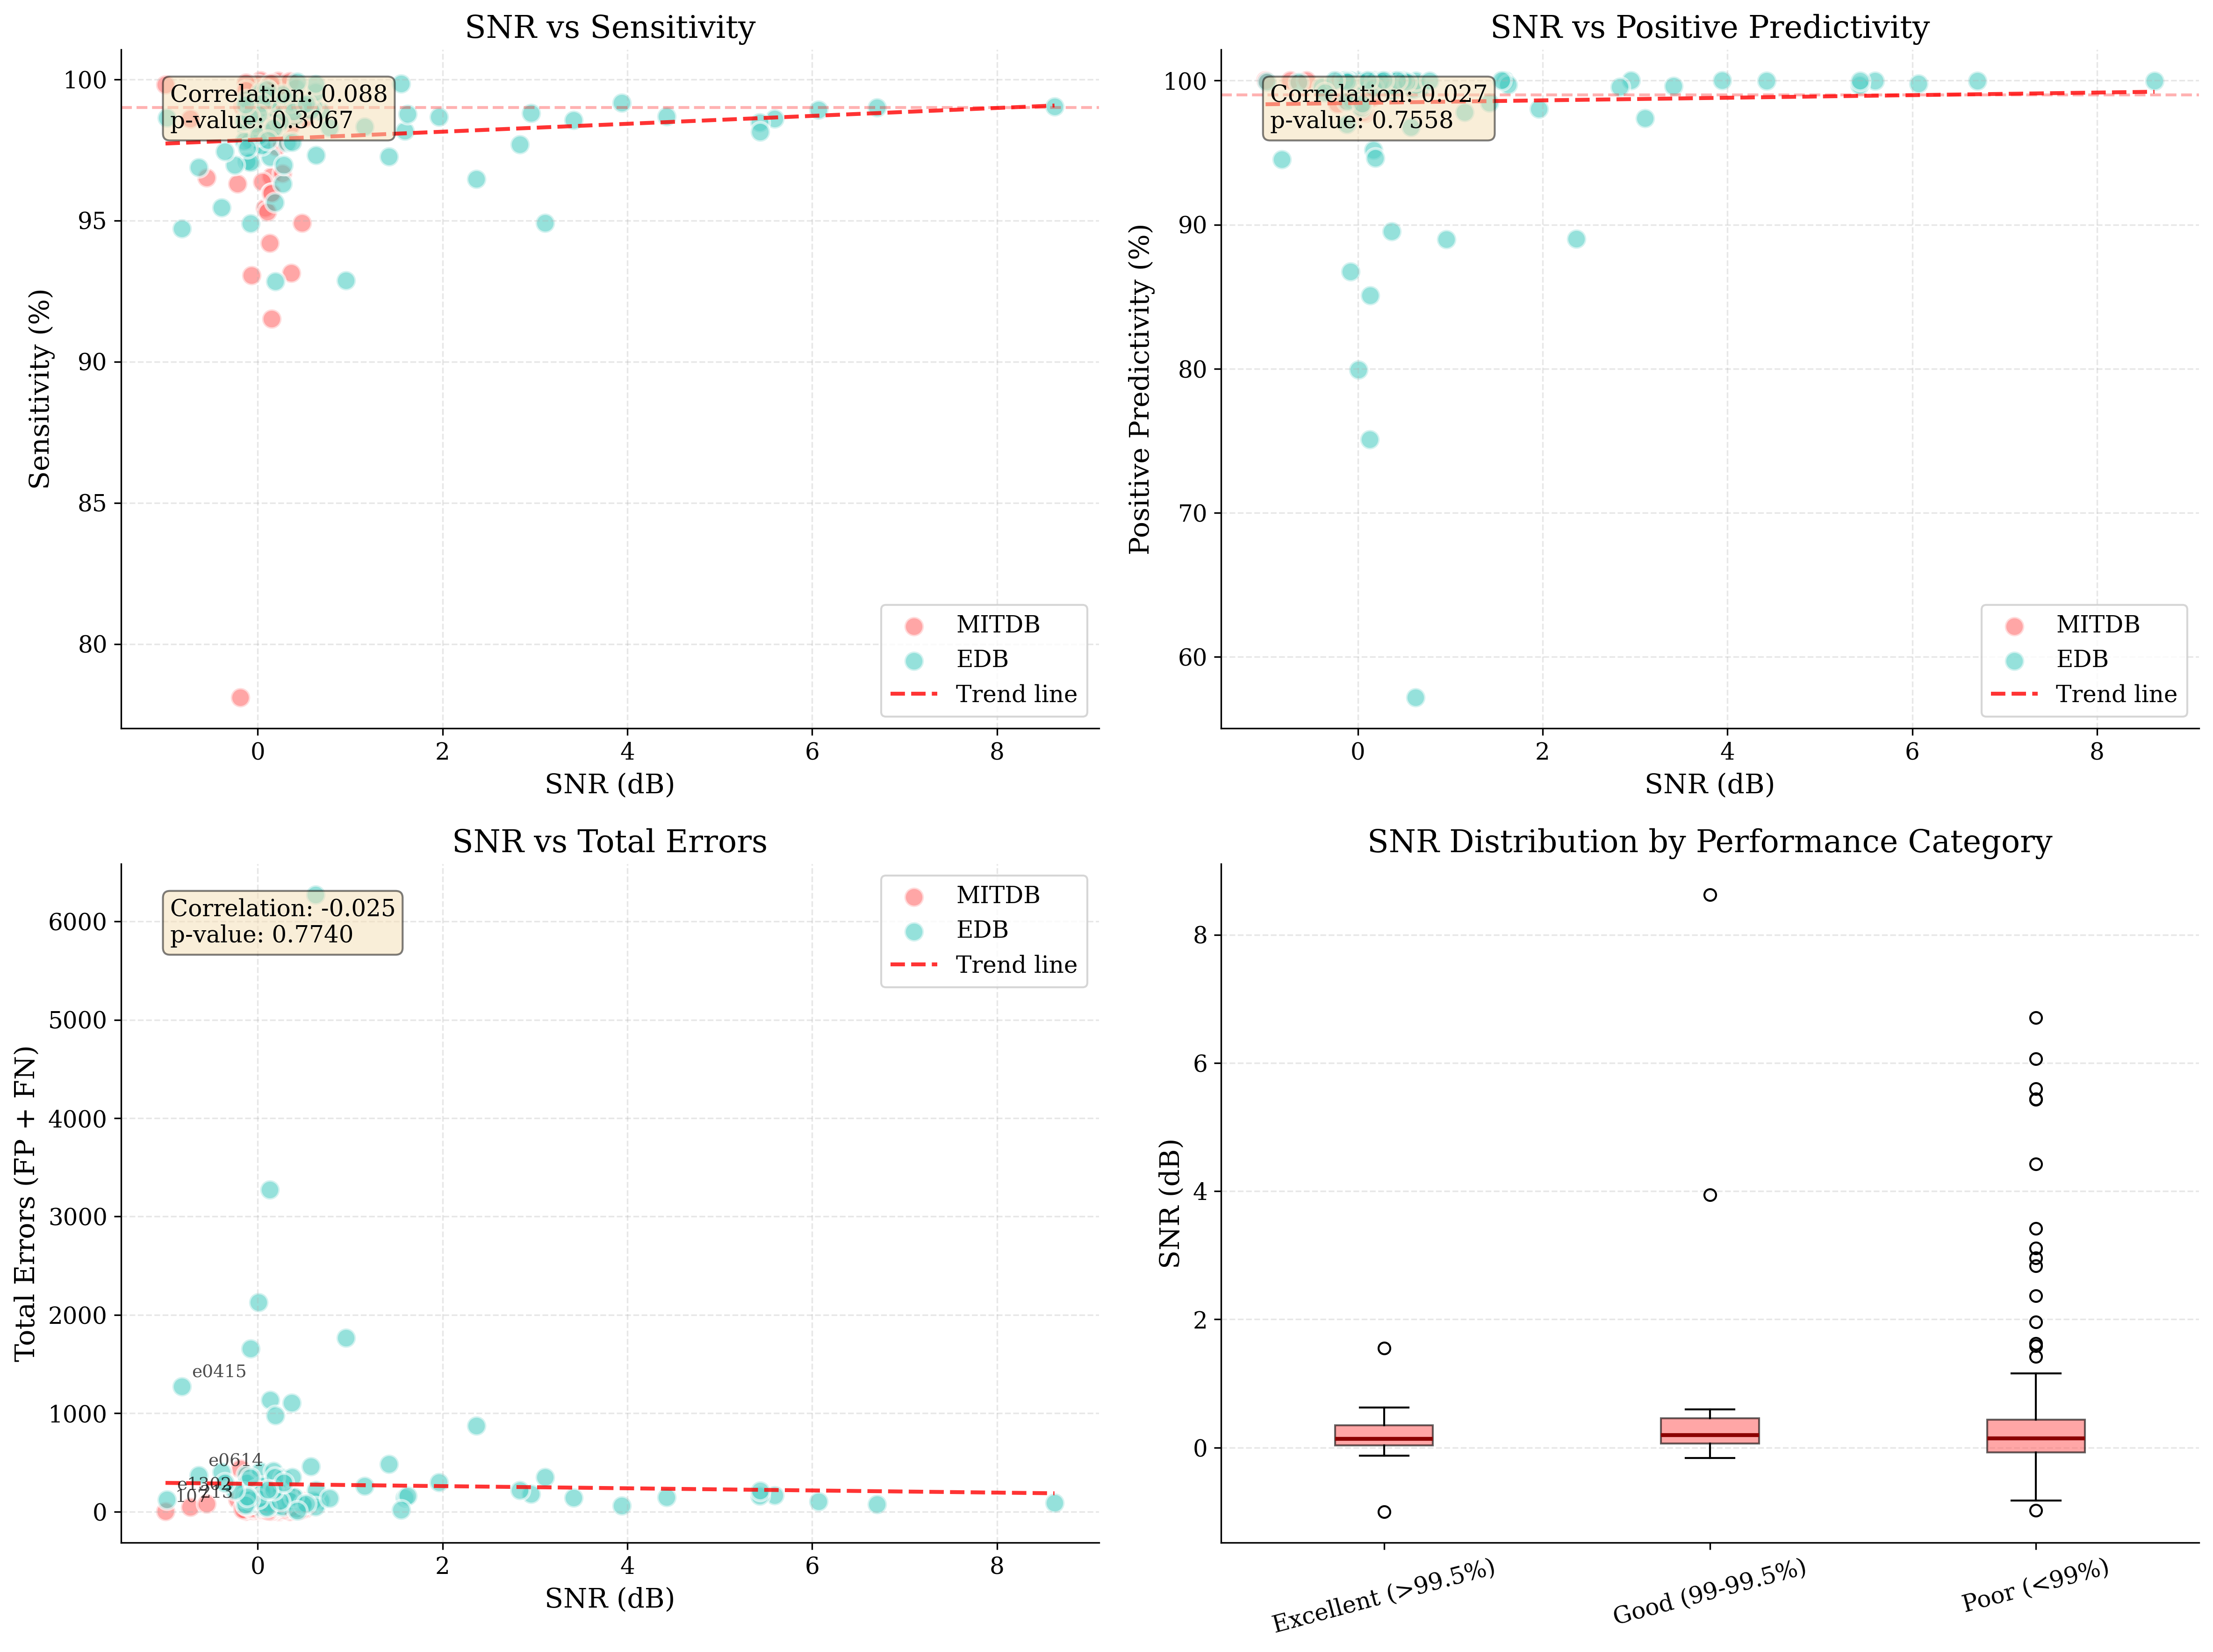


SNR-PERFORMANCE CORRELATION ANALYSIS

SNR vs Sensitivity:
  Correlation coefficient: 0.0880
  P-value: 0.306749
  Interpretation: Not significant correlation

SNR vs Positive Predictivity:
  Correlation coefficient: 0.0268
  P-value: 0.755770
  Interpretation: Not significant correlation

SNR vs Total Errors:
  Correlation coefficient: -0.0248
  P-value: 0.773953
  Interpretation: Not significant correlation

Mean SNR by Performance Category:
  Excellent (>99.5%): 0.19 ± 0.45 dB (n=21)
  Good (99-99.5%): 0.69 ± 1.83 dB (n=25)
  Poor (<99%): 0.67 ± 1.55 dB (n=91)


In [12]:
# --- PLOT 7: SNR vs Performance Correlation ---
fig7, ((ax7a, ax7b), (ax7c, ax7d)) = plt.subplots(2, 2, figsize=(16, 12))

# Separate by database
mitdb_snr = df_snr[df_snr['Database'] == 'MITDB']
edb_snr = df_snr[df_snr['Database'] == 'EDB']

# Plot 1: SNR vs Sensitivity
ax7a.scatter(mitdb_snr['SNR_dB'], mitdb_snr['Sensitivity_%'], 
            s=100, alpha=0.6, color=color_my, label='MITDB', edgecolor='white', linewidth=1.5)
ax7a.scatter(edb_snr['SNR_dB'], edb_snr['Sensitivity_%'], 
            s=100, alpha=0.6, color=color_paper, label='EDB', edgecolor='white', linewidth=1.5)

# Add trend line
from scipy.stats import pearsonr
if len(df_snr) > 2:
    z = np.polyfit(df_snr['SNR_dB'].dropna(), df_snr['Sensitivity_%'][df_snr['SNR_dB'].notna()], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df_snr['SNR_dB'].min(), df_snr['SNR_dB'].max(), 100)
    ax7a.plot(x_line, p(x_line), "r--", alpha=0.8, linewidth=2, label='Trend line')
    
    # Calculate correlation
    corr, p_value = pearsonr(df_snr['SNR_dB'].dropna(), df_snr['Sensitivity_%'][df_snr['SNR_dB'].notna()])
    ax7a.text(0.05, 0.95, f'Correlation: {corr:.3f}\np-value: {p_value:.4f}', 
             transform=ax7a.transAxes, fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax7a.set_xlabel('SNR (dB)', fontsize=14)
ax7a.set_ylabel('Sensitivity (%)', fontsize=14)
ax7a.set_title('SNR vs Sensitivity', fontsize=16)
ax7a.legend(fontsize=12)
ax7a.grid(True, linestyle='--', alpha=0.3)
ax7a.axhline(99, color='red', linestyle='--', alpha=0.3, label='99% target')

# Plot 2: SNR vs Positive Predictivity
ax7b.scatter(mitdb_snr['SNR_dB'], mitdb_snr['Positive_Predictivity_%'], 
            s=100, alpha=0.6, color=color_my, label='MITDB', edgecolor='white', linewidth=1.5)
ax7b.scatter(edb_snr['SNR_dB'], edb_snr['Positive_Predictivity_%'], 
            s=100, alpha=0.6, color=color_paper, label='EDB', edgecolor='white', linewidth=1.5)

# Add trend line
if len(df_snr) > 2:
    z = np.polyfit(df_snr['SNR_dB'].dropna(), df_snr['Positive_Predictivity_%'][df_snr['SNR_dB'].notna()], 1)
    p = np.poly1d(z)
    ax7b.plot(x_line, p(x_line), "r--", alpha=0.8, linewidth=2, label='Trend line')
    
    # Calculate correlation
    corr, p_value = pearsonr(df_snr['SNR_dB'].dropna(), df_snr['Positive_Predictivity_%'][df_snr['SNR_dB'].notna()])
    ax7b.text(0.05, 0.95, f'Correlation: {corr:.3f}\np-value: {p_value:.4f}', 
             transform=ax7b.transAxes, fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax7b.set_xlabel('SNR (dB)', fontsize=14)
ax7b.set_ylabel('Positive Predictivity (%)', fontsize=14)
ax7b.set_title('SNR vs Positive Predictivity', fontsize=16)
ax7b.legend(fontsize=12)
ax7b.grid(True, linestyle='--', alpha=0.3)
ax7b.axhline(99, color='red', linestyle='--', alpha=0.3)

# Plot 3: SNR vs Total Errors
ax7c.scatter(mitdb_snr['SNR_dB'], mitdb_snr['Total_Errors'], 
            s=100, alpha=0.6, color=color_my, label='MITDB', edgecolor='white', linewidth=1.5)
ax7c.scatter(edb_snr['SNR_dB'], edb_snr['Total_Errors'], 
            s=100, alpha=0.6, color=color_paper, label='EDB', edgecolor='white', linewidth=1.5)

# Add trend line
if len(df_snr) > 2:
    z = np.polyfit(df_snr['SNR_dB'].dropna(), df_snr['Total_Errors'][df_snr['SNR_dB'].notna()], 1)
    p = np.poly1d(z)
    ax7c.plot(x_line, p(x_line), "r--", alpha=0.8, linewidth=2, label='Trend line')
    
    # Calculate correlation
    corr, p_value = pearsonr(df_snr['SNR_dB'].dropna(), df_snr['Total_Errors'][df_snr['SNR_dB'].notna()])
    ax7c.text(0.05, 0.95, f'Correlation: {corr:.3f}\np-value: {p_value:.4f}', 
             transform=ax7c.transAxes, fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax7c.set_xlabel('SNR (dB)', fontsize=14)
ax7c.set_ylabel('Total Errors (FP + FN)', fontsize=14)
ax7c.set_title('SNR vs Total Errors', fontsize=16)
ax7c.legend(fontsize=12)
ax7c.grid(True, linestyle='--', alpha=0.3)

# Annotate worst performers
worst_snr_records = df_snr.nsmallest(5, 'SNR_dB')
for idx, row in worst_snr_records.iterrows():
    ax7c.annotate(row['Record'], 
                 (row['SNR_dB'], row['Total_Errors']), 
                 xytext=(5, 5), textcoords='offset points',
                 fontsize=9, alpha=0.7)

# Plot 4: SNR Distribution by Performance Category
# Categorize records by sensitivity
df_snr['Performance'] = df_snr['Sensitivity_%'].apply(
    lambda x: 'Excellent (>99.5%)' if x > 99.5 else ('Good (99-99.5%)' if x > 99 else 'Poor (<99%)')
)

categories = ['Excellent (>99.5%)', 'Good (99-99.5%)', 'Poor (<99%)']
snr_by_category = [df_snr[df_snr['Performance'] == cat]['SNR_dB'].dropna().values for cat in categories]

bp = ax7d.boxplot(snr_by_category, labels=categories, patch_artist=True,
                  boxprops=dict(facecolor=color_my, alpha=0.6),
                  medianprops=dict(color='darkred', linewidth=2))

ax7d.set_ylabel('SNR (dB)', fontsize=14)
ax7d.set_title('SNR Distribution by Performance Category', fontsize=16)
ax7d.grid(axis='y', linestyle='--', alpha=0.3)
ax7d.tick_params(axis='x', rotation=15)

plt.tight_layout()
fig7.savefig('../figures/plot7_snr_correlation.png', dpi=300)
plt.show()

# Print correlation summary
print("\n" + "="*80)
print("SNR-PERFORMANCE CORRELATION ANALYSIS")
print("="*80)

corr_se, p_se = pearsonr(df_snr['SNR_dB'].dropna(), df_snr['Sensitivity_%'][df_snr['SNR_dB'].notna()])
corr_pp, p_pp = pearsonr(df_snr['SNR_dB'].dropna(), df_snr['Positive_Predictivity_%'][df_snr['SNR_dB'].notna()])
corr_err, p_err = pearsonr(df_snr['SNR_dB'].dropna(), df_snr['Total_Errors'][df_snr['SNR_dB'].notna()])

print(f"\nSNR vs Sensitivity:")
print(f"  Correlation coefficient: {corr_se:.4f}")
print(f"  P-value: {p_se:.6f}")
print(f"  Interpretation: {'Significant' if p_se < 0.05 else 'Not significant'} correlation")

print(f"\nSNR vs Positive Predictivity:")
print(f"  Correlation coefficient: {corr_pp:.4f}")
print(f"  P-value: {p_pp:.6f}")
print(f"  Interpretation: {'Significant' if p_pp < 0.05 else 'Not significant'} correlation")

print(f"\nSNR vs Total Errors:")
print(f"  Correlation coefficient: {corr_err:.4f}")
print(f"  P-value: {p_err:.6f}")
print(f"  Interpretation: {'Significant' if p_err < 0.05 else 'Not significant'} correlation")

print("\nMean SNR by Performance Category:")
for cat in categories:
    cat_data = df_snr[df_snr['Performance'] == cat]['SNR_dB'].dropna()
    if len(cat_data) > 0:
        print(f"  {cat}: {cat_data.mean():.2f} ± {cat_data.std():.2f} dB (n={len(cat_data)})")

print("="*80)